In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
np.random.seed(42)

n = 500

data = pd.DataFrame({
    "StudentID": [f"STU{i:03d}" for i in range(1, n + 1)],
    "Gender": np.random.choice(["Female", "Male"], n),
    "StudyHours": np.round(np.random.uniform(0.5, 8, n), 1),
    "Attendance": np.round(np.random.uniform(40, 100, n), 1),
    "AssignmentCompletion": np.round(np.random.uniform(30, 100, n), 1),
    "PreviousScore": np.round(np.random.uniform(25, 100, n), 1),
    "SleepHours": np.round(np.random.uniform(4, 10, n), 1),
    "Participation": np.random.randint(1, 6, n)
})

# Create a synthetic academic performance score
sleep_score = 100 - abs(data["SleepHours"] - 7) * 15

performance = (
    0.30 * data["PreviousScore"]
    + 0.20 * (data["StudyHours"] / 8 * 100)
    + 0.20 * data["Attendance"]
    + 0.15 * data["AssignmentCompletion"]
    + 0.10 * (data["Participation"] / 5 * 100)
    + 0.05 * sleep_score
    + np.random.normal(0, 8, n)
)

# Generate subject marks
data["MathScore"] = np.clip(
    performance + np.random.normal(0, 8, n), 0, 100
).round(1)

data["EnglishScore"] = np.clip(
    performance + np.random.normal(0, 8, n), 0, 100
).round(1)

data["ScienceScore"] = np.clip(
    performance + np.random.normal(0, 8, n), 0, 100
).round(1)

# Calculate average marks
subject_columns = ["MathScore", "EnglishScore", "ScienceScore"]
data["AverageMarks"] = data[subject_columns].mean(axis=1).round(1)

# Assign performance category
def categorize_performance(marks):
    if marks >= 75:
        return "High"
    elif marks >= 50:
        return "Medium"
    else:
        return "Low"

data["PerformanceCategory"] = data["AverageMarks"].apply(
    categorize_performance
)

print("Dataset created successfully!")
print("Dataset shape:", data.shape)
display(data.head(10))

Dataset created successfully!
Dataset shape: (500, 13)


,StudentID,Gender,StudyHours,Attendance,AssignmentCompletion,PreviousScore,SleepHours,Participation,MathScore,EnglishScore,ScienceScore,AverageMarks,PerformanceCategory
0,STU001,Female,2.7,47.0,85.8,65.1,4.6,4,52.2,51.5,50.6,51.4,Medium
1,STU002,Male,3.4,96.4,63.7,41.1,9.5,3,63.1,65.5,65.4,64.7,Medium
2,STU003,Female,6.9,77.7,38.2,25.9,8.0,3,63.6,46.0,50.7,53.4,Medium
3,STU004,Female,2.9,60.1,38.8,43.1,9.0,1,49.6,59.3,57.3,55.4,Medium
4,STU005,Female,1.8,48.4,78.0,98.2,9.3,1,57.0,66.7,61.9,61.9,Medium
5,STU006,Male,4.7,87.6,60.1,85.1,7.4,4,63.3,68.9,66.0,66.1,Medium
6,STU007,Female,7.5,77.2,44.0,97.0,7.1,4,88.5,97.4,100.0,95.3,High
7,STU008,Female,5.7,72.0,64.4,61.6,6.6,1,52.8,50.7,61.4,55.0,Medium
8,STU009,Female,4.8,93.6,34.5,33.2,5.9,1,61.2,69.2,64.1,64.8,Medium
9,STU010,Male,1.2,87.3,70.7,66.1,6.6,2,58.3,51.9,64.4,58.2,Medium


In [3]:
print("Dataset Information:")
data.info()

print("\nMissing Values:")
display(data.isnull().sum().to_frame("Missing Values"))

print("\nDuplicate Rows:", data.duplicated().sum())

# Remove duplicate rows if any
data = data.drop_duplicates().copy()

print("\nSummary Statistics:")
display(data.describe().round(2))

print("\nPerformance Category Count:")
display(
    data["PerformanceCategory"]
    .value_counts()
    .rename_axis("Category")
    .to_frame("Students")
)

# Key performance indicators
total_students = len(data)
average_marks = data["AverageMarks"].mean()
pass_percentage = (data["AverageMarks"] >= 40).mean() * 100
high_performers = (data["PerformanceCategory"] == "High").sum()
average_attendance = data["Attendance"].mean()

print("\n========== STUDENT PERFORMANCE KPIs ==========")
print("Total Students:", total_students)
print(f"Average Marks: {average_marks:.2f}")
print(f"Pass Percentage (40+): {pass_percentage:.2f}%")
print("High Performers:", high_performers)
print(f"Average Attendance: {average_attendance:.2f}%")

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   StudentID             500 non-null    object 
 1   Gender                500 non-null    object 
 2   StudyHours            500 non-null    float64
 3   Attendance            500 non-null    float64
 4   AssignmentCompletion  500 non-null    float64
 5   PreviousScore         500 non-null    float64
 6   SleepHours            500 non-null    float64
 7   Participation         500 non-null    int64  
 8   MathScore             500 non-null    float64
 9   EnglishScore          500 non-null    float64
 10  ScienceScore          500 non-null    float64
 11  AverageMarks          500 non-null    float64
 12  PerformanceCategory   500 non-null    object 
dtypes: float64(9), int64(1), object(3)
memory usage: 50.9+ KB

Missing Values:


,Missing Values
StudentID,0
Gender,0
StudyHours,0
Attendance,0
AssignmentCompletion,0
PreviousScore,0
SleepHours,0
Participation,0
MathScore,0
EnglishScore,0



Duplicate Rows: 0

Summary Statistics:


,StudyHours,Attendance,AssignmentCompletion,PreviousScore,SleepHours,Participation,MathScore,EnglishScore,ScienceScore,AverageMarks
count,500.00,500.00,500.00,500.00,500.00,500.00,500.00,500.00,500.00,500.00
mean,4.23,70.49,64.49,63.09,6.93,2.93,62.90,64.29,63.58,63.59
std,2.20,17.75,20.25,21.71,1.72,1.41,15.51,15.41,15.28,13.99
min,0.60,40.30,30.30,25.20,4.00,1.00,12.80,19.20,21.90,22.60
25%,2.30,54.22,46.40,44.05,5.60,2.00,52.38,53.30,52.78,52.80
50%,4.30,71.60,64.80,64.15,6.90,3.00,63.30,64.70,63.90,64.75
75%,6.10,86.12,80.72,82.15,8.40,4.00,73.53,75.70,74.40,73.45
max,8.00,99.90,100.00,99.90,10.00,5.00,100.00,100.00,100.00,96.50



Performance Category Count:


,Students
Category,
Medium,297
High,107
Low,96



========== STUDENT PERFORMANCE KPIs ==========
Total Students: 500
Average Marks: 63.59
Pass Percentage (40+): 95.40%
High Performers: 107
Average Attendance: 70.49%


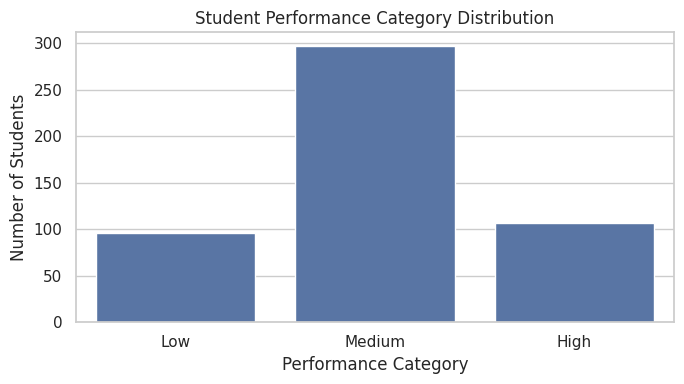

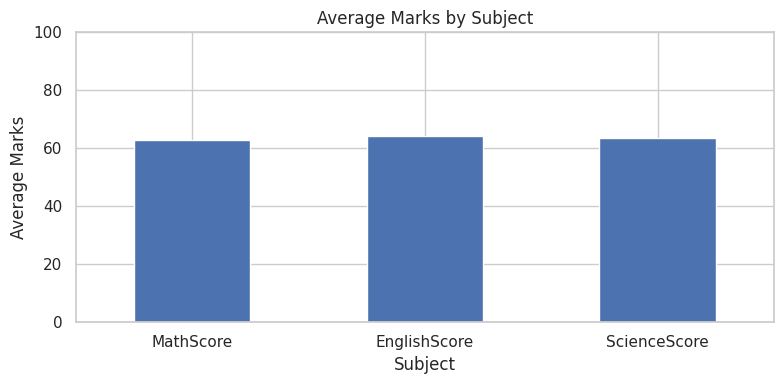

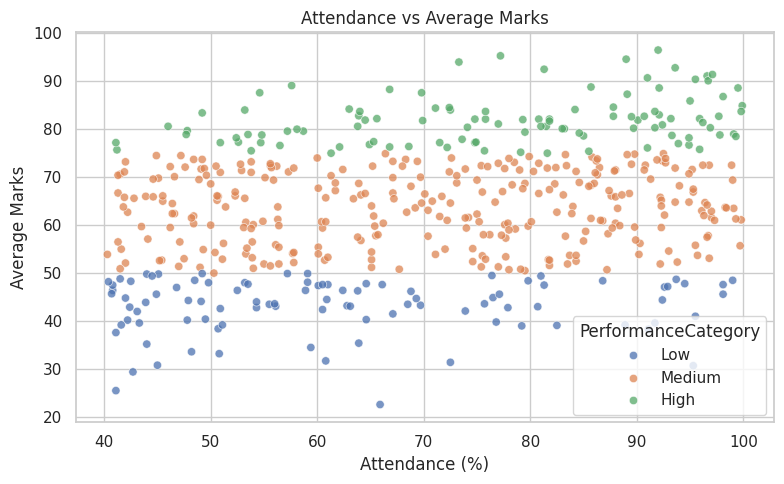

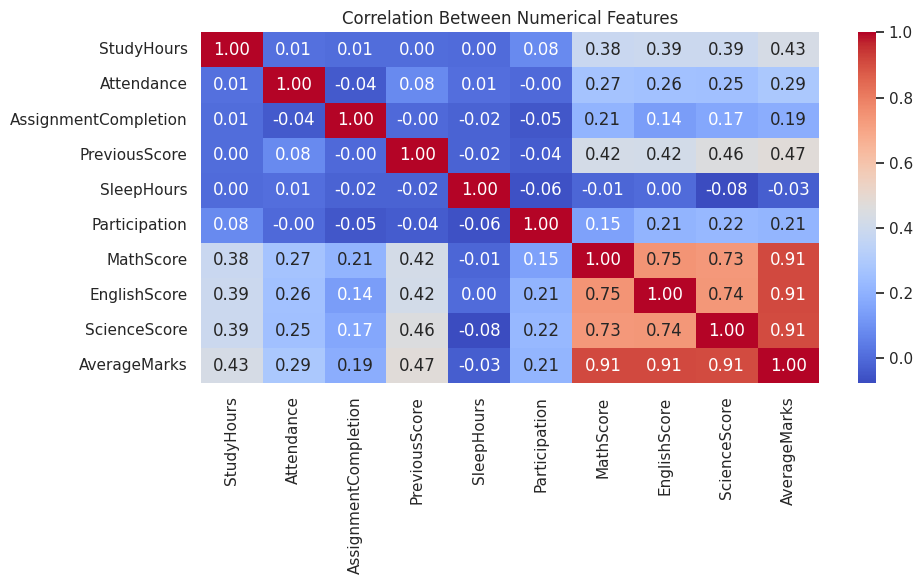

In [4]:
sns.set_theme(style="whitegrid")

# Chart 1: Performance category distribution
plt.figure(figsize=(7, 4))
sns.countplot(
    data=data,
    x="PerformanceCategory",
    order=["Low", "Medium", "High"]
)
plt.title("Student Performance Category Distribution")
plt.xlabel("Performance Category")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.show()

# Chart 2: Average marks by subject
subject_averages = data[
    ["MathScore", "EnglishScore", "ScienceScore"]
].mean()

plt.figure(figsize=(8, 4))
subject_averages.plot(kind="bar")
plt.title("Average Marks by Subject")
plt.xlabel("Subject")
plt.ylabel("Average Marks")
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

# Chart 3: Attendance vs average marks
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=data,
    x="Attendance",
    y="AverageMarks",
    hue="PerformanceCategory",
    hue_order=["Low", "Medium", "High"],
    alpha=0.75
)
plt.title("Attendance vs Average Marks")
plt.xlabel("Attendance (%)")
plt.ylabel("Average Marks")
plt.tight_layout()
plt.show()

# Chart 4: Correlation heatmap
numeric_data = data.select_dtypes(include="number").drop(
    columns=["StudentID"], errors="ignore"
)

plt.figure(figsize=(10, 6))
sns.heatmap(
    numeric_data.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Between Numerical Features")
plt.tight_layout()
plt.show()

In [5]:
# Features used to predict performance
features = [
    "StudyHours",
    "Attendance",
    "AssignmentCompletion",
    "PreviousScore",
    "SleepHours",
    "Participation"
]

X = data[features]
y = data["PerformanceCategory"]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Train the model
model = RandomForestClassifier(
    n_estimators=200,
    max_depth=8,
    random_state=42,
    class_weight="balanced"
)

model.fit(X_train, y_train)

# Make predictions
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print("Model training completed!")
print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print(f"Test Accuracy: {accuracy * 100:.2f}%")

Model training completed!
Training records: 400
Testing records: 100
Test Accuracy: 60.00%


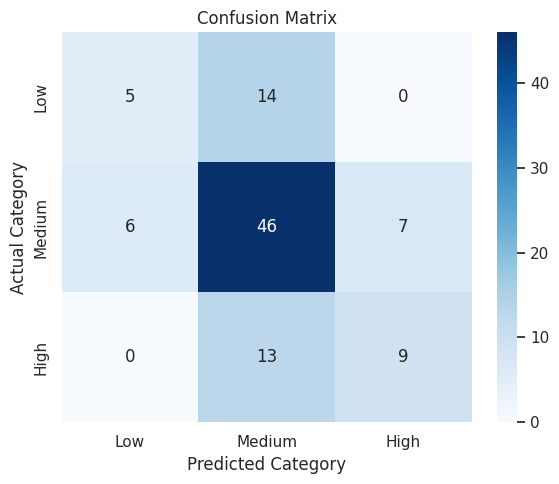

Classification Report:
              precision    recall  f1-score   support

         Low       0.45      0.26      0.33        19
      Medium       0.63      0.78      0.70        59
        High       0.56      0.41      0.47        22

    accuracy                           0.60       100
   macro avg       0.55      0.48      0.50       100
weighted avg       0.58      0.60      0.58       100



In [6]:
labels = ["Low", "Medium", "High"]

cm = confusion_matrix(y_test, y_pred, labels=labels)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)
plt.title("Confusion Matrix")
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.tight_layout()
plt.show()

print("Classification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        labels=labels,
        zero_division=0
    )
)

,Feature,Importance
0,StudyHours,0.247087
3,PreviousScore,0.242269
1,Attendance,0.178390
2,AssignmentCompletion,0.141894
4,SleepHours,0.106765
5,Participation,0.083596


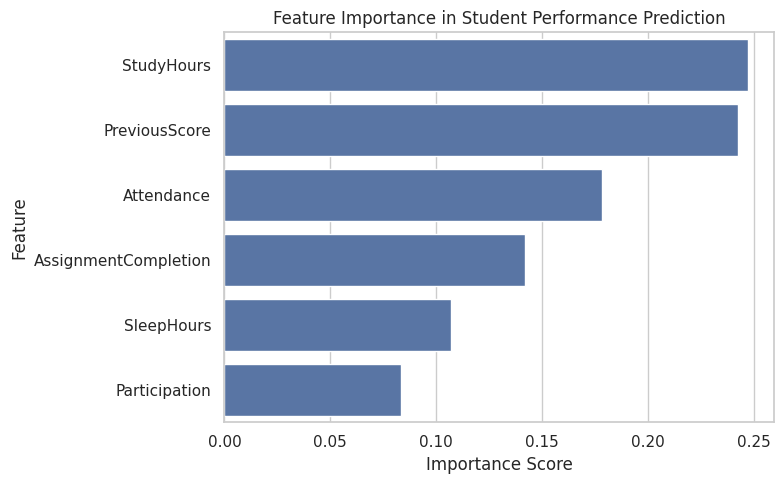

In [7]:
importance = pd.DataFrame({
    "Feature": features,
    "Importance": model.feature_importances_
}).sort_values("Importance", ascending=False)

display(importance)

plt.figure(figsize=(8, 5))
sns.barplot(
    data=importance,
    x="Importance",
    y="Feature"
)
plt.title("Feature Importance in Student Performance Prediction")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [8]:
# Enter sample values for a new student
new_student = pd.DataFrame([{
    "StudyHours": 5.0,
    "Attendance": 85.0,
    "AssignmentCompletion": 90.0,
    "PreviousScore": 70.0,
    "SleepHours": 7.0,
    "Participation": 4
}])

predicted_category = model.predict(new_student)[0]
probabilities = model.predict_proba(new_student)[0]

print("========== STUDENT PERFORMANCE PREDICTION ==========")
display(new_student)

print("Predicted Performance Category:", predicted_category)

print("\nModel probability estimates:")
for category, probability in zip(model.classes_, probabilities):
    print(f"{category}: {probability * 100:.2f}%")

========== STUDENT PERFORMANCE PREDICTION ==========


,StudyHours,Attendance,AssignmentCompletion,PreviousScore,SleepHours,Participation
0,5.0,85.0,90.0,70.0,7.0,4


Predicted Performance Category: High

Model probability estimates:
High: 53.04%
Low: 0.96%
Medium: 46.00%


In [9]:
# Top 10 students
top_students = data.sort_values(
    "AverageMarks", ascending=False
).head(10)

print("========== TOP 10 STUDENTS ==========")
display(
    top_students[
        ["StudentID", "AverageMarks", "Attendance",
         "PerformanceCategory"]
    ]
)

# Students who may need additional academic support
low_performers = data[
    data["PerformanceCategory"] == "Low"
].sort_values("AverageMarks")

print("========== STUDENTS FOR ACADEMIC REVIEW ==========")
display(
    low_performers[
        ["StudentID", "AverageMarks", "Attendance",
         "StudyHours", "PerformanceCategory"]
    ].head(20)
)

# Save reports
data.to_csv("student_performance_dataset.csv", index=False)
importance.to_csv("feature_importance.csv", index=False)

predictions = X_test.copy()
predictions["ActualCategory"] = y_test.to_numpy()
predictions["PredictedCategory"] = y_pred
predictions.to_csv("model_predictions.csv", index=False)

print("CSV reports saved successfully!")

========== TOP 10 STUDENTS ==========


,StudentID,AverageMarks,Attendance,PerformanceCategory
399,STU400,96.5,92.0,High
6,STU007,95.3,77.2,High
156,STU157,94.6,89.0,High
191,STU192,94.0,73.3,High
155,STU156,92.8,93.6,High
436,STU437,92.5,81.3,High
470,STU471,91.4,97.1,High
262,STU263,91.1,96.6,High
257,STU258,90.7,91.0,High
272,STU273,90.4,95.5,High


========== STUDENTS FOR ACADEMIC REVIEW ==========


,StudentID,AverageMarks,Attendance,StudyHours,PerformanceCategory
472,STU473,22.6,65.9,1.0,Low
186,STU187,25.5,41.1,1.0,Low
444,STU445,29.4,42.7,1.4,Low
49,STU050,30.7,95.3,1.1,Low
210,STU211,30.8,45.0,1.4,Low
251,STU252,31.4,72.5,4.5,Low
76,STU077,31.7,60.8,4.7,Low
266,STU267,33.2,50.8,3.3,Low
247,STU248,33.6,48.2,1.1,Low
453,STU454,34.5,59.4,1.5,Low


CSV reports saved successfully!


In [10]:
from google.colab import files

files.download("student_performance_dataset.csv")
files.download("feature_importance.csv")
files.download("model_predictions.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>